# Performing Facial Recognition with Deep Learning
Baseline face-recognition CNN on the ORL (AT&T) Database of Faces for Face2Gene.

All training ran on CPU with a small CNN and a few dozen epochs, so the notebook runs in a few minutes.

## Step 1: Import the relevant packages and collect dependencies

In [1]:
import os, json, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
SEED=42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs('screens', exist_ok=True)
RESULTS={}
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## Step 2: Upload and import the data
The `ORL_faces.npz` file ships with a pre-made 240/160 train/test split of 20 subjects (12 and 8 images each). I pool all 400 images first so that I can build my own train/validation/test framework in Step 4.

In [2]:
data = np.load('data/ORL_faces.npz')
for k in data.files: print(k, data[k].shape, data[k].dtype)
X_all = np.concatenate([data['trainX'], data['testX']]).astype('float32')
y_all = np.concatenate([data['trainY'], data['testY']]).astype('int64')
print('Pooled:', X_all.shape, y_all.shape, '| subjects:', len(np.unique(y_all)), '| images per subject:', np.unique(np.bincount(y_all)))
print('pixel range:', X_all.min(), X_all.max())

testY (160,) uint8
testX (160, 10304) float64


trainX (240, 10304) float64
trainY (240,) uint8
Pooled: (400, 10304) (400,) | subjects: 20 | images per subject: [20]
pixel range: 0.0 244.0


The file holds flattened 112x92 grey-scale images (10304 pixels). Pooling gives 400 images for 20 subjects with 20 images each, so the classes are perfectly balanced.

## Step 3: View a few images to get a sense of the data

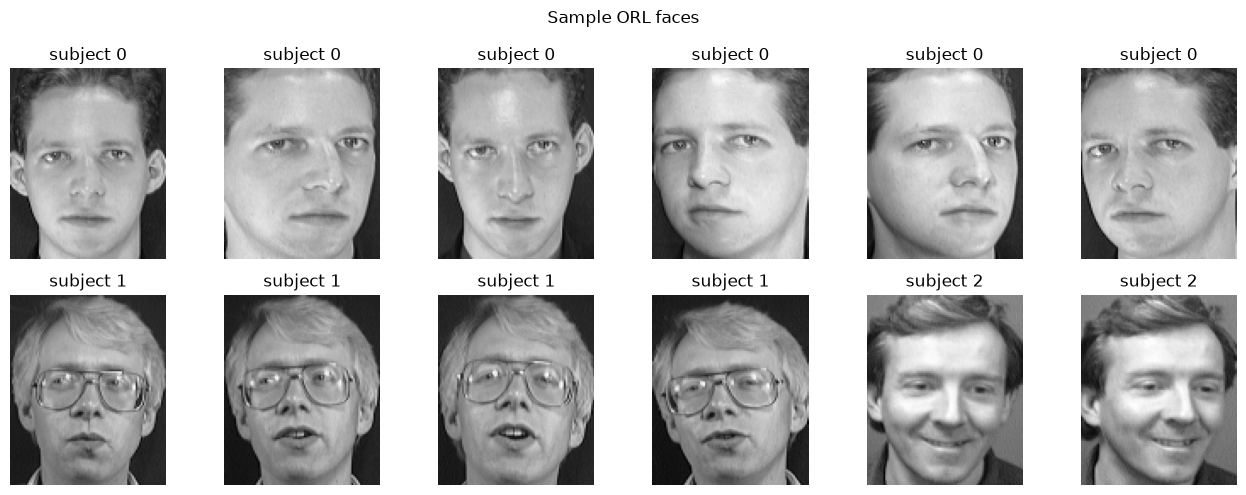

In [3]:
H, W = 112, 92
imgs = X_all.reshape(-1, H, W)
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, i in zip(axes.ravel(), [0,1,2,3,4,5, 20,21,22,23,24,25]):
    ax.imshow(imgs[i], cmap='gray'); ax.set_title(f'subject {y_all[i]}'); ax.axis('off')
plt.suptitle('Sample ORL faces')
plt.tight_layout(); plt.savefig('screens/01_sample_faces.png', dpi=110); plt.show()

The images show frontal faces on a dark background with variation in expression, pose and glasses for the same subject, which is what the classifier has to cope with.

## Step 4: Create a validation framework (train / validation / test)
A stratified 70% / 15% / 15% split keeps all 20 subjects in each part: 14 / 3 / 3 images per subject.

In [4]:
idx = np.arange(len(y_all))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=y_all[tmp_idx], random_state=SEED)
print('train', len(tr_idx), 'val', len(va_idx), 'test', len(te_idx))
print('per-subject counts  train:', np.unique(np.bincount(y_all[tr_idx])), 'val:', np.unique(np.bincount(y_all[va_idx])), 'test:', np.unique(np.bincount(y_all[te_idx])))

train 280 val 60 test 60
per-subject counts  train: [14] val: [3] test: [3]


## Step 5: Transformations to prepare data for the CNN
Scale pixels to [0, 1] and reshape to (112, 92, 1). Labels stay as integers and are used with sparse categorical cross-entropy, so no one-hot encoding is needed.

In [5]:
def prep(ix):
    return (X_all[ix] / 255.0).reshape(-1, H, W, 1).astype('float32'), y_all[ix]
X_tr, y_tr = prep(tr_idx); X_va, y_va = prep(va_idx); X_te, y_te = prep(te_idx)
NUM_CLASSES = len(np.unique(y_all))
print(X_tr.shape, X_va.shape, X_te.shape, 'classes', NUM_CLASSES)

(280, 112, 92, 1) (60, 112, 92, 1) (60, 112, 92, 1) classes 20


## Step 6: Build the CNN (convolutional, pooling and fully connected layers)
Model A is a plain baseline: three Conv+Pool blocks, then Flatten and Dense layers. Model B (used in Step 9) adds data augmentation, batch normalisation and dropout.

In [6]:
def build_cnn(augment=False, dropout=0.0, bn=False):
    inp = keras.Input((H, W, 1))
    x = inp
    if augment:
        x = layers.RandomTranslation(0.08, 0.08, fill_mode='nearest')(x)
        x = layers.RandomRotation(0.04, fill_mode='nearest')(x)
        x = layers.RandomZoom(0.08, fill_mode='nearest')(x)
        x = layers.RandomContrast(0.15)(x)
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, padding='same', activation=None if bn else 'relu')(x)   # convolutional layer
        if bn: x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)                                                   # pooling layer
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation='relu')(x)                                         # fully connected layer
    if dropout: x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return keras.Model(inp, out)
model_a = build_cnn()
model_a.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 112, 92, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 112, 92, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 56, 46, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 56, 46, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 28, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 23, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 19712)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     5,046,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         5,140 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,144,340 (19.62 MB)

 Trainable params: 5,144,340 (19.62 MB)

 Non-trainable params: 0 (0.00 B)

## Step 7: Train the model (baseline, Model A)

In [7]:
model_a.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_a = model_a.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=30, batch_size=16, verbose=2)

Epoch 1/30


18/18 - 9s - 527ms/step - accuracy: 0.0429 - loss: 3.0154 - val_accuracy: 0.1500 - val_loss: 2.9515


Epoch 2/30


18/18 - 3s - 158ms/step - accuracy: 0.2179 - loss: 2.6939 - val_accuracy: 0.4500 - val_loss: 2.0059


Epoch 3/30


18/18 - 2s - 134ms/step - accuracy: 0.7321 - loss: 0.9398 - val_accuracy: 0.7667 - val_loss: 0.7918


... (50 outputs left out)

Epoch 29/30


18/18 - 4s - 239ms/step - accuracy: 1.0000 - loss: 8.4779e-06 - val_accuracy: 1.0000 - val_loss: 0.0028


Epoch 30/30


18/18 - 4s - 240ms/step - accuracy: 1.0000 - loss: 7.6009e-06 - val_accuracy: 1.0000 - val_loss: 0.0027


## Step 8: Plot the results (Model A)

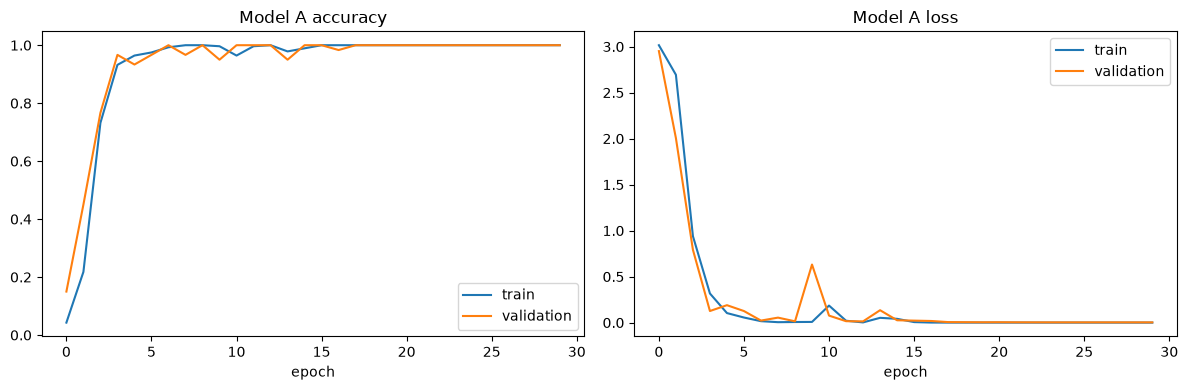

Model A  best val acc = 1.0000   test acc = 0.9667


In [8]:
def plot_hist(h, title, fn):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history['accuracy'], label='train'); ax[0].plot(h.history['val_accuracy'], label='validation'); ax[0].set_title(title+' accuracy'); ax[0].set_xlabel('epoch'); ax[0].legend()
    ax[1].plot(h.history['loss'], label='train'); ax[1].plot(h.history['val_loss'], label='validation'); ax[1].set_title(title+' loss'); ax[1].set_xlabel('epoch'); ax[1].legend()
    plt.tight_layout(); plt.savefig(fn, dpi=110); plt.show()
plot_hist(hist_a, 'Model A', 'screens/02_model_A_training.png')
te_a = model_a.evaluate(X_te, y_te, verbose=0)[1]; va_a = max(hist_a.history['val_accuracy'])
print(f'Model A  best val acc = {va_a:.4f}   test acc = {te_a:.4f}')
RESULTS['Model A test accuracy'] = round(float(te_a), 4)

## Step 9: Iterate until accuracy is above 90%
If Model A does not clear 90% on the held-out test set, I move to Model B: data augmentation, dropout and a learning-rate schedule (a first attempt with batch norm and early stopping on validation accuracy was unstable on 280 training images, so I dropped both). The test set is only used for the final score, never for choosing epochs.

In [9]:
model_b = build_cnn(augment=True, dropout=0.4, bn=False)
model_b.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cbs = [keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.5, patience=5, min_lr=1e-5)]
hist_b = model_b.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=60, batch_size=16, callbacks=cbs, verbose=0)
print('epochs run:', len(hist_b.history['loss']))

epochs run: 60


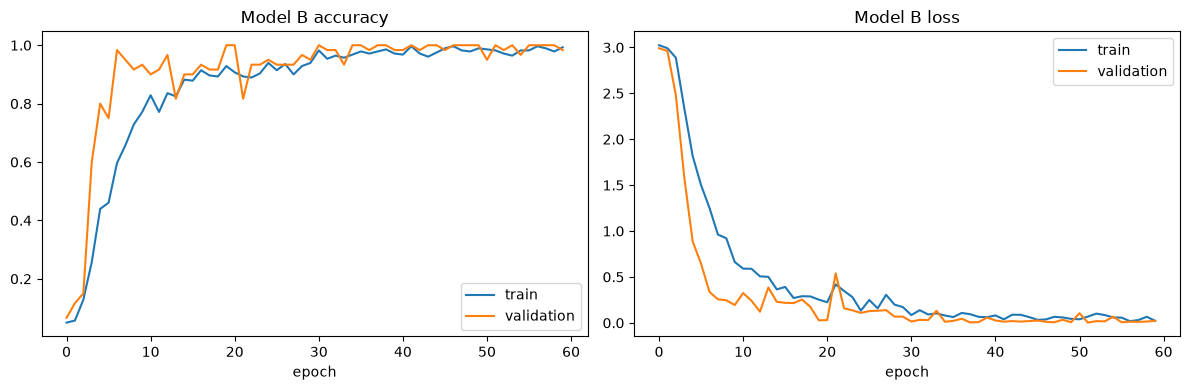

Model B  train acc = 1.0000   val acc = 0.9833   test acc = 1.0000
Target > 90% on test: MET


In [10]:
plot_hist(hist_b, 'Model B', 'screens/03_model_B_training.png')
te_b = model_b.evaluate(X_te, y_te, verbose=0)[1]; va_b = model_b.evaluate(X_va, y_va, verbose=0)[1]; tr_b = model_b.evaluate(X_tr, y_tr, verbose=0)[1]
print(f'Model B  train acc = {tr_b:.4f}   val acc = {va_b:.4f}   test acc = {te_b:.4f}')
print('Target > 90% on test:', 'MET' if te_b > 0.90 else 'NOT MET')
RESULTS['Model B train accuracy'] = round(float(tr_b), 4)
RESULTS['Model B validation accuracy'] = round(float(va_b), 4)
RESULTS['Model B test accuracy'] = round(float(te_b), 4)
RESULTS['Epochs run (Model B)'] = len(hist_b.history['loss'])
RESULTS['>90% target met on test'] = bool(te_b > 0.90)

              precision    recall  f1-score   support

           0      1.000     1.000     1.000         3
           1      1.000     1.000     1.000         3
           2      1.000     1.000     1.000         3
           3      1.000     1.000     1.000         3
           4      1.000     1.000     1.000         3
           5      1.000     1.000     1.000         3
           6      1.000     1.000     1.000         3
           7      1.000     1.000     1.000         3
           8      1.000     1.000     1.000         3
           9      1.000     1.000     1.000         3
          10      1.000     1.000     1.000         3
          11      1.000     1.000     1.000         3
          12      1.000     1.000     1.000         3
          13      1.000     1.000     1.000         3
          14      1.000     1.000     1.000         3
          15      1.000     1.000     1.000         3
          16      1.000     1.000     1.000         3
          17      1.000    

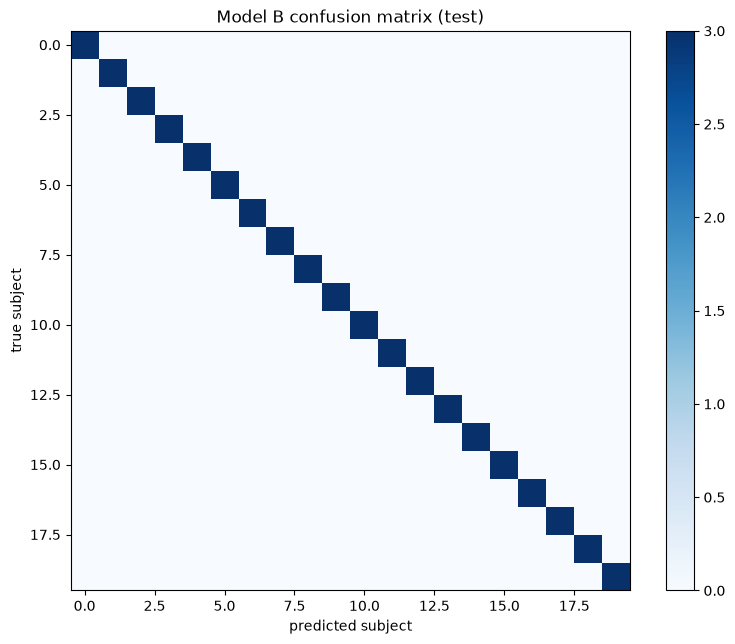

misclassified test images: 0 of 60


In [11]:
pred = model_b.predict(X_te, verbose=0).argmax(1)
print(classification_report(y_te, pred, digits=3, zero_division=0))
cm = confusion_matrix(y_te, pred)
plt.figure(figsize=(8, 6.5)); plt.imshow(cm, cmap='Blues'); plt.colorbar(); plt.xlabel('predicted subject'); plt.ylabel('true subject'); plt.title('Model B confusion matrix (test)')
plt.tight_layout(); plt.savefig('screens/04_confusion_matrix.png', dpi=110); plt.show()
wrong = np.where(pred != y_te)[0]
if len(wrong):
    n = min(len(wrong), 6)
    fig, axes = plt.subplots(1, n, figsize=(2.2*n, 3), squeeze=False)
    for ax, i in zip(axes.ravel(), wrong[:n]):
        ax.imshow(X_te[i, :, :, 0], cmap='gray'); ax.set_title(f'true {y_te[i]} / pred {pred[i]}'); ax.axis('off')
    plt.savefig('screens/05_misclassified.png', dpi=110); plt.show()
print('misclassified test images:', len(wrong), 'of', len(y_te))

## Final metrics table

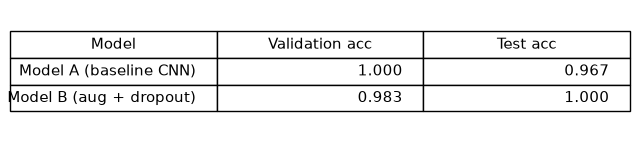

{'Model A test accuracy': 0.9667, 'Model B train accuracy': 1.0, 'Model B validation accuracy': 0.9833, 'Model B test accuracy': 1.0, 'Epochs run (Model B)': 60, '>90% target met on test': True, 'Metrics': {'columns': ['Model', 'Validation acc', 'Test acc'], 'rows': [['Model A (baseline CNN)', '1.000', '0.967'], ['Model B (aug + dropout)', '0.983', '1.000']]}}


In [12]:
rows = [['Model A (baseline CNN)', f'{va_a:.3f}', f'{te_a:.3f}'],
        ['Model B (aug + dropout)', f'{va_b:.3f}', f'{te_b:.3f}']]
fig, ax = plt.subplots(figsize=(8, 1.6)); ax.axis('off')
t = ax.table(cellText=rows, colLabels=['Model', 'Validation acc', 'Test acc'], loc='center'); t.scale(1, 1.6); t.auto_set_font_size(False); t.set_fontsize(11)
plt.savefig('screens/06_metrics_table.png', dpi=130, bbox_inches='tight'); plt.show()
RESULTS['Metrics'] = {'columns': ['Model', 'Validation acc', 'Test acc'], 'rows': rows}
json.dump(RESULTS, open('results.json', 'w'), indent=1)
print(RESULTS)

## Conclusion
See the printed numbers above. The test set (60 images, 3 per subject) is small, so one image is worth about 1.7 percentage points. The result is a baseline: in a clinical setting the model would need a larger and more diverse set of faces and an open-set (verification) approach rather than closed-set classification of 20 known subjects.